# 04 · Predictive LTV

**Business question:** how much revenue (and margin) will each customer generate in the next 12 months? With that we can define how much to pay to acquire a customer (maximum CAC) per channel and prioritize the base in the CRM.

**Design:** cutoff on Oct 13, 2025, with features computed up to that date. The target is **paid revenue in the following 12 months** (Oct 13, 2025 to Oct 13, 2026). LightGBM with a Tweedie loss, suited to values with many zeros and a long tail, compared with the heuristic "the next 12 months repeat the last 12".

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import lightgbm as lgb
from scipy.stats import spearmanr
from sklearn.model_selection import KFold
from utils_nb import sql, configurar_graficos, brl, CORES, COR_REAL, COR_PREVISTO, COR_DESTAQUE

configurar_graficos()

In [2]:
ped = sql("""
WITH unif AS (SELECT cliente_id, tipo_cliente, tipo_pessoa, origem_cadastro,
                     IF(cpf IS NULL, cliente_id, MIN(cliente_id) OVER (PARTITION BY cpf)) AS cliente FROM clientes)
SELECT u.cliente, u.tipo_cliente, u.tipo_pessoa, u.origem_cadastro, p.pedido_id, p.criado_em, p.total, p.desconto,
       p.cupom_id IS NOT NULL AS cupom,
       (SELECT SUM(i.total_item - i.quantidade * i.custo_unitario) FROM itens_pedido i WHERE i.pedido_id = p.pedido_id) - p.desconto
         - (f.custo_real - p.frete) AS margem,
       COALESCE(a.canal, IF(p.sessao_id IS NULL, '(não rastreado)', 'Direct')) AS canal_lc
FROM pedidos p
JOIN unif u USING (cliente_id)
JOIN fretes f ON f.pedido_id = p.pedido_id
LEFT JOIN atribuicoes a ON a.pedido_id = p.pedido_id AND a.modelo = 'last_click'
WHERE p.pedido_teste = 0 AND p.status IN ('pago','enviado','entregue','devolvido')""")
ped["criado_em"] = pd.to_datetime(ped["criado_em"])
print(f"{len(ped):,} pedidos pagos | margem de contribuição média {ped.margem.sum() / ped.total.sum():.1%} da receita "
      "(margem dos itens - descontos - subsídio de frete)")

133,649 pedidos pagos | margem de contribuição média 46.9% da receita (margem dos itens - descontos - subsídio de frete)


## Customer features with Polars

Feature engineering uses **Polars** (*lazy* API): the per-customer aggregations over 90, 180 and 365-day windows run in a single pass over the orders.

In [3]:
import polars as pl
import datetime as dt

pl_ped = pl.from_pandas(ped)

def montar(T, horizonte=365):
    T = pd.Timestamp(T).to_pydatetime()
    hist = pl_ped.lazy().filter(pl.col("criado_em") <= T).sort("criado_em")
    janela = lambda d: pl.col("criado_em") > T - dt.timedelta(days=d)
    X = (hist.group_by("cliente").agg(
            recencia=(pl.lit(T) - pl.col("criado_em").max()).dt.total_days(),
            antiguidade=(pl.lit(T) - pl.col("criado_em").min()).dt.total_days(),
            pedidos=pl.len(),
            receita=pl.col("total").sum(),
            margem=pl.col("margem").sum(),
            ticket_medio=pl.col("total").mean(),
            primeiro_ticket=pl.col("total").first(),
            pct_cupom=pl.col("cupom").cast(pl.Float64).mean(),
            intervalo_medio=pl.col("criado_em").diff().dt.total_days().mean(),
            **{f"receita_{d}d": pl.col("total").filter(janela(d)).sum() for d in (90, 180, 365)},
            **{f"pedidos_{d}d": pl.col("total").filter(janela(d)).len() for d in (90, 180, 365)},
            tipo_cliente=pl.col("tipo_cliente").first(),
            tipo_pessoa=pl.col("tipo_pessoa").first(),
            origem=pl.col("origem_cadastro").first(),
            canal_aquisicao=pl.col("canal_lc").first(),
         ).collect().to_pandas().set_index("cliente"))
    tipo = X.pop("tipo_cliente")
    for t in ["hobby", "costureira", "atelie", "confeccao"]:
        X[f"tipo_{t}"] = tipo.eq(t).astype(int)
    X["pj"] = X.pop("tipo_pessoa").eq("PJ").astype(int)
    X["legado"] = X.pop("origem").eq("importacao_legado").astype(int)
    fut = (pl_ped.lazy().filter((pl.col("criado_em") > T) & (pl.col("criado_em") <= T + dt.timedelta(days=horizonte)))
           .group_by("cliente").agg(pl.col("total").sum(), pl.col("margem").sum()).collect().to_pandas().set_index("cliente"))
    y = fut["total"].reindex(X.index).fillna(0)
    ym = fut["margem"].reindex(X.index).fillna(0)
    return X, y, ym

X, y, ym = montar("2025-10-13")
feats = [c for c in X.columns if c != "canal_aquisicao"]
print(f"{len(X):,} clientes no corte | {(y > 0).mean():.1%} compraram nos 12 meses seguintes | receita futura média {brl(y.mean())}")

30,358 clientes no corte | 27.9% compraram nos 12 meses seguintes | receita futura média R$ 237


## Cross-validation (5 folds) at the Oct/2025 cutoff

In [4]:
params = dict(objective="tweedie", tweedie_variance_power=1.3, learning_rate=0.03, num_leaves=31,
              min_data_in_leaf=40, feature_fraction=0.85, bagging_fraction=0.8, bagging_freq=1, lambda_l2=5,
              verbose=-1, seed=7)
oof = pd.Series(0.0, index=X.index)
for tr, te in KFold(5, shuffle=True, random_state=7).split(X):
    m = lgb.train(params, lgb.Dataset(X.iloc[tr][feats], y.iloc[tr]), num_boost_round=600)
    oof.iloc[te] = m.predict(X.iloc[te][feats])
heur = X["receita_365d"]

def metricas(p):
    ordem = np.argsort(-p.values)
    top10 = y.values[ordem][: len(y) // 10].sum() / y.sum()
    return {"MAE (R$)": np.abs(y - p).mean(), "Erro no total": p.sum() / y.sum() - 1,
            "Spearman": spearmanr(y, p).correlation, "Receita futura capturada pelo top 10%": top10}

aval = pd.DataFrame({"Heurística (últimos 12 meses)": metricas(heur), "LightGBM Tweedie": metricas(oof)}).T
aval.style.format({"MAE (R$)": "{:,.0f}", "Erro no total": "{:+.1%}", "Spearman": "{:.3f}",
                   "Receita futura capturada pelo top 10%": "{:.1%}"})

,MAE (R$),Erro no total,Spearman,Receita futura capturada pelo top 10%
Heurística (últimos 12 meses),390,+75.5%,0.367,51.1%
LightGBM Tweedie,243,-11.5%,0.452,60.2%


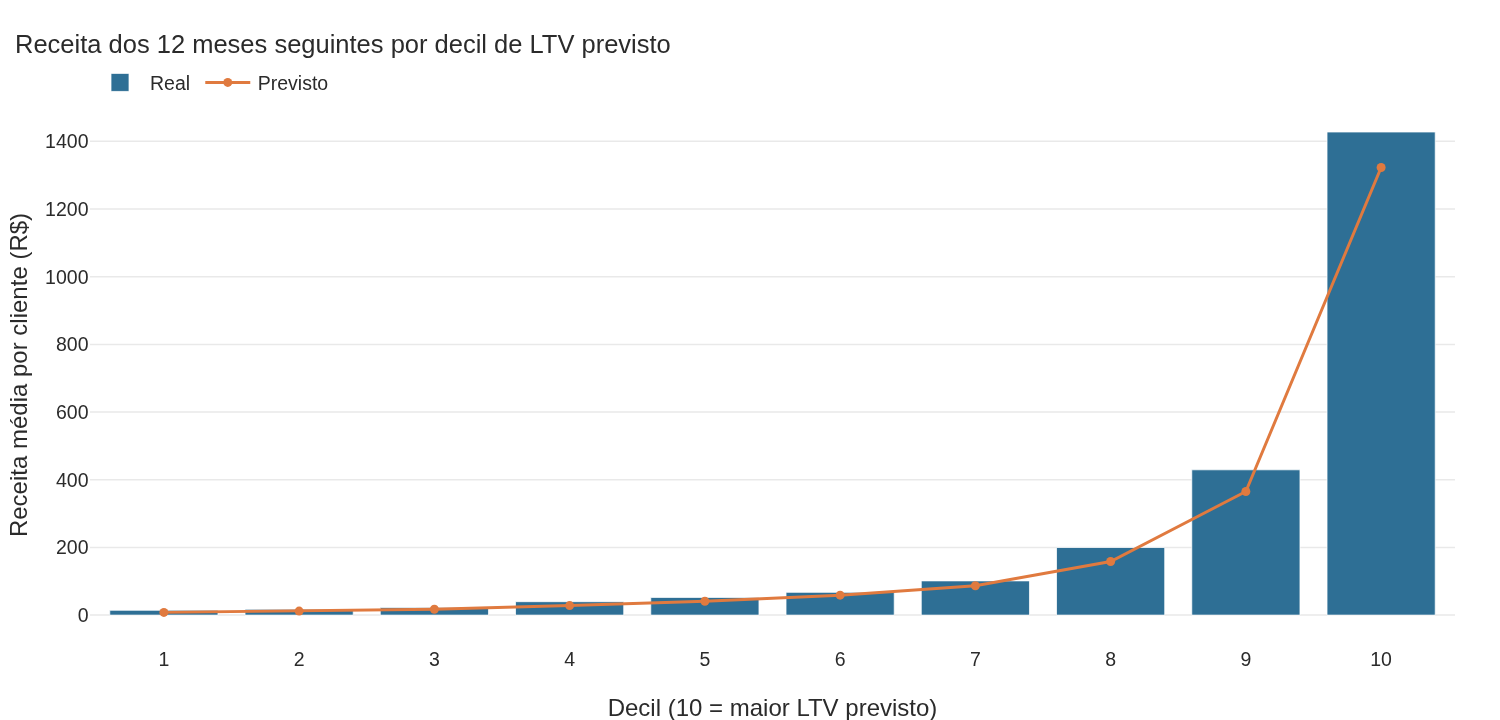

In [5]:
dec = pd.DataFrame({"prev": oof, "real": y}).assign(decil=lambda d: pd.qcut(d.prev.rank(method="first"), 10, labels=range(1, 11)))
g = dec.groupby("decil", observed=True)[["prev", "real"]].mean()
fig = go.Figure()
fig.add_bar(x=g.index.astype(str), y=g.real, name="Real", marker_color=COR_REAL)
fig.add_scatter(x=g.index.astype(str), y=g.prev, name="Previsto", mode="lines+markers", line=dict(color=COR_PREVISTO))
fig.update_layout(title="Receita dos 12 meses seguintes por decil de LTV previsto", xaxis_title="Decil (10 = maior LTV previsto)",
                  yaxis_title="Receita média por cliente (R$)")
fig.show()

## Current LTV of the base and LTV x CAC by acquisition channel

The model is retrained with the Oct/2025 cutoff and applied to today's features (Oct 13, 2026) to predict the next 12 months. The predicted margin uses each customer's historical margin/revenue ratio.

**CAC per channel** divides the platform's spend by the new customers whose first purchase had its last click in that channel, over the last 12 months. It is an attribution view and tends to favor bottom-of-funnel channels (see notebook 05).

In [6]:
m_full = lgb.train(params, lgb.Dataset(X[feats], y), num_boost_round=600)
Xh, _, _ = montar("2026-10-13 23:59:59", horizonte=1)  # inclui as compras feitas durante o dia 13/10
Xh["ltv12_receita"] = m_full.predict(Xh[feats])
taxa_margem = (Xh["margem"] / Xh["receita"]).clip(0.2, 0.7).fillna(0.45)
Xh["ltv12_margem"] = Xh["ltv12_receita"] * taxa_margem

# clientes adquiridos nos últimos 12 meses: canal da primeira compra
novos = ped.sort_values("criado_em").drop_duplicates("cliente")
novos = novos[novos.criado_em > pd.Timestamp("2025-10-13")]
inv = sql("""SELECT 'meta' plat, SUM(investimento) inv FROM meta_metricas_diarias WHERE data > '2025-10-13'
             UNION ALL SELECT 'google', SUM(investimento) FROM google_metricas_diarias WHERE data > '2025-10-13'""").set_index("plat").inv
plat = {"Paid Social": "meta", "Paid Search": "google", "Cross-network": "google", "Paid Shopping": "google", "Paid Video": "google"}
novos["plat"] = novos.canal_lc.map(plat)
cac = inv / novos.groupby("plat").size()
tab = novos.assign(ltv_margem=Xh.loc[novos.cliente, "ltv12_margem"].values + novos.margem.values,
                   ltv_receita=Xh.loc[novos.cliente, "ltv12_receita"].values + novos.total.values) \
    .groupby("canal_lc").agg(clientes_novos=("cliente", "size"), ltv_receita_24m=("ltv_receita", "mean"),
                             ltv_margem_24m=("ltv_margem", "mean"), ticket_1a_compra=("total", "mean"))
tab["cac_last_click"] = tab.index.map(lambda c: cac.get(plat.get(c)))
tab["ltv_margem_sobre_cac"] = tab.ltv_margem_24m / tab.cac_last_click
tab.sort_values("clientes_novos", ascending=False).style.format({
    "ltv_receita_24m": "R$ {:,.0f}", "ltv_margem_24m": "R$ {:,.0f}", "ticket_1a_compra": "R$ {:,.0f}",
    "cac_last_click": "R$ {:,.0f}", "ltv_margem_sobre_cac": "{:.1f}x"}, na_rep="—")

,clientes_novos,ltv_receita_24m,ltv_margem_24m,ticket_1a_compra,cac_last_click,ltv_margem_sobre_cac
canal_lc,,,,,,
Paid Social,3156,R$ 475,R$ 214,R$ 203,R$ 302,0.7x
Paid Search,2721,R$ 584,R$ 267,R$ 242,R$ 160,1.7x
Organic Search,2697,R$ 548,R$ 250,R$ 225,—,—
(não rastreado),2475,R$ 636,R$ 294,R$ 254,—,—
Organic Social,1767,R$ 541,R$ 248,R$ 220,—,—
Direct,1677,R$ 570,R$ 261,R$ 235,—,—
Cross-network,1583,R$ 581,R$ 266,R$ 240,R$ 160,1.7x
Referral,393,R$ 592,R$ 271,R$ 208,—,—
WhatsApp,207,R$ 520,R$ 236,R$ 207,—,—


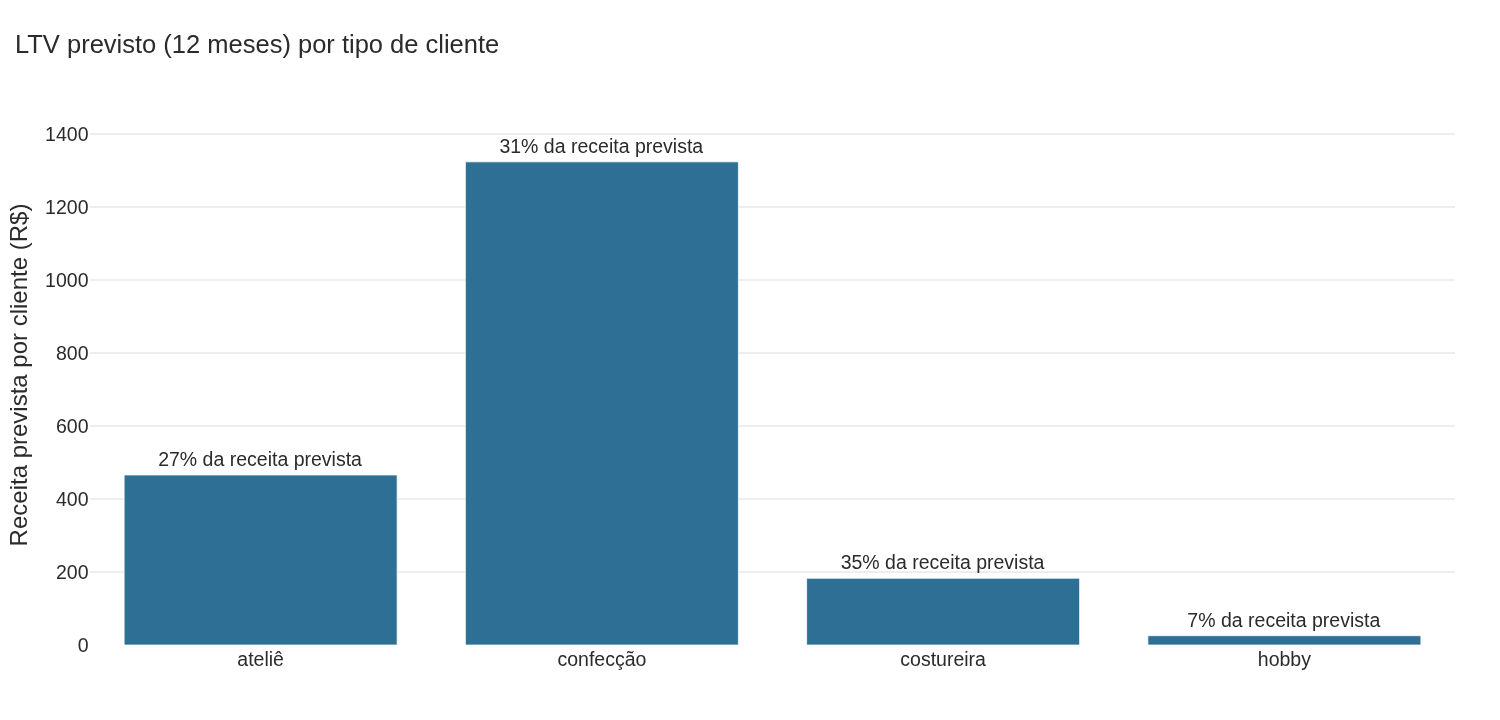

Top 10% dos clientes concentram 66.0% da receita prevista para os próximos 12 meses
Receita prevista da base atual nos próximos 12 meses: R$ 8.613.022


In [7]:
por_tipo = Xh.assign(tipo=np.select([Xh.tipo_hobby == 1, Xh.tipo_costureira == 1, Xh.tipo_atelie == 1], ["hobby", "costureira", "ateliê"], "confecção")) \
    .groupby("tipo").agg(clientes=("ltv12_receita", "size"), ltv12_receita=("ltv12_receita", "mean"), ltv12_margem=("ltv12_margem", "mean"),
                         receita_total_prevista=("ltv12_receita", "sum"))
por_tipo["pct_receita_prevista"] = por_tipo.receita_total_prevista / por_tipo.receita_total_prevista.sum()
fig = px.bar(por_tipo.reset_index(), x="tipo", y="ltv12_receita", text=por_tipo["pct_receita_prevista"].map("{:.0%} da receita prevista".format).values,
             title="LTV previsto (12 meses) por tipo de cliente", labels={"tipo": "", "ltv12_receita": "Receita prevista por cliente (R$)"})
fig.update_traces(marker_color=COR_REAL, textposition="outside")
fig.show()
top = Xh.sort_values("ltv12_receita", ascending=False)
print(f"Top 10% dos clientes concentram {top.ltv12_receita.iloc[:len(top) // 10].sum() / top.ltv12_receita.sum():.1%} da receita prevista para os próximos 12 meses")
print(f"Receita prevista da base atual nos próximos 12 meses: {brl(Xh.ltv12_receita.sum())}")

## Business conclusions

1. **LightGBM predicts LTV much better than the heuristic.** The heuristic "the next 12 months repeat the last 12" misses the total by +76%; the model misses by -12%, with an MAE of R$ 243 against R$ 390. The 10% of customers with the highest predicted LTV concentrated 60% of the following real revenue.
2. **Future revenue is highly concentrated:** the 10% of customers with the highest predicted LTV should generate 66% of the R$ 8.6 million expected from the current base in the next 12 months. This is the group for priority service and not to lose to stockouts or late deliveries.
3. **By last click, Google pays off and Meta does not:** margin LTV over CAC of 1.7x in Paid Search and Cross-network against 0.7x in Paid Social. But last click misattributes prospecting: notebook 05's pause test shows an iROAS of ~3 for Meta prospecting. Use this table to compare the *value* of customers by channel (similar across channels: R$ 214 to R$ 294 of margin in 24 months), not to cut budget.
4. **Average contribution margin of 47% of revenue.** With it, the maximum CAC to break even in 24 months is around R$ 210 to R$ 290, depending on the channel.